# Data Science Tool Mastery: Practical Exercises
**Task 4, Notebook 1 of 2** - AI ML Research Specialist Internship

Each exercise states a task, solves it with an industry-standard tool, and ends with an automated **check** (an assertion comparing against a reference implementation or a known property). All checks are collected in a scoreboard at the end.

| Section | Tools | Exercises |
|---|---|---|
| A | NumPy | broadcasting, SVD-based PCA from scratch, least squares, vectorised bootstrap |
| B | Pandas, SQL (sqlite3), statsmodels | method chaining, groupby/transform, pivot, time series, SQL equivalence, forecasting |
| C | Matplotlib, Seaborn | small multiples, custom multi-panel figure, regression and PCA plots |
| D | SciPy, statsmodels | ANOVA + Tukey, OLS with diagnostics, permutation test |
| E | scikit-learn, LightGBM | pipelines, cross-validation, tuning, data-leakage demonstration, learning curves |

Data: real public datasets (Palmer penguins, Box-Jenkins airline passengers); see `data/SOURCE.md`.

In [1]:
import sys, json, time, sqlite3, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib, matplotlib.pyplot as plt
import seaborn as sns, scipy, sklearn, statsmodels, lightgbm
from scipy import stats
import statsmodels.api as sm, statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold, GridSearchCV, cross_validate,
                                     cross_val_score, learning_curve)
from sklearn.feature_selection import SelectKBest, f_classif
from lightgbm import LGBMClassifier
from scipy.spatial.distance import cdist

sys.path.insert(0, str(Path.cwd().parent / "src")) if Path.cwd().name == "notebooks" else sys.path.insert(0, str(Path.cwd() / "src"))
from toolkit import Winsorizer, CorrelationFilter
from toolkit.data import load_penguins, load_flights

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "outputs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
CHECKS, RESULTS = [], {}

def check(exercise, tool, description, condition, detail=""):
    """Record a verified claim; the notebook fails loudly if it does not hold."""
    CHECKS.append({"exercise": exercise, "tool": tool, "check": description, "passed": bool(condition), "detail": detail})
    assert condition, f"CHECK FAILED: {exercise} - {description} {detail}"
    print(f"[PASS] {exercise}: {description}" + (f"  ({detail})" if detail else ""))

def save_fig(fig, name):
    fig.tight_layout(); fig.savefig(FIG / name, dpi=130, bbox_inches="tight"); plt.show()

versions = {"Python": sys.version.split()[0], "NumPy": np.__version__, "Pandas": pd.__version__, "SciPy": scipy.__version__,
            "statsmodels": statsmodels.__version__, "scikit-learn": sklearn.__version__, "LightGBM": lightgbm.__version__,
            "Matplotlib": matplotlib.__version__, "Seaborn": sns.__version__}
RESULTS["versions"] = versions
pd.Series(versions, name="version").to_frame()

,version
Python,3.12.3
NumPy,2.4.4
Pandas,3.0.2
SciPy,1.17.1
statsmodels,0.15.0
scikit-learn,1.8.0
LightGBM,4.7.0
Matplotlib,3.10.8
Seaborn,0.13.2


## A. NumPy

### A1. Broadcasting: pairwise distance matrix
**Task.** Compute all pairwise Euclidean distances between 400 five-dimensional points without a Python loop, and compare with a naive double loop and `scipy.spatial.distance.cdist`.

In [2]:
rng = np.random.default_rng(SEED)
P = rng.normal(size=(400, 5))

def pairwise_loop(P):
    n = len(P); D = np.empty((n, n))
    for i in range(n):
        for j in range(n):
            D[i, j] = np.sqrt(((P[i] - P[j]) ** 2).sum())
    return D

def pairwise_broadcast(P):
    diff = P[:, None, :] - P[None, :, :]          # (n,1,d) - (1,n,d) -> (n,n,d)
    return np.sqrt((diff ** 2).sum(axis=-1))

t0 = time.perf_counter(); D_loop = pairwise_loop(P); t_loop = time.perf_counter() - t0
t0 = time.perf_counter(); D_bc = pairwise_broadcast(P); t_bc = time.perf_counter() - t0
D_ref = cdist(P, P)
RESULTS["a1_speedup"] = t_loop / t_bc
check("A1", "NumPy", "broadcast result equals loop result and SciPy cdist", np.allclose(D_loop, D_bc) and np.allclose(D_bc, D_ref))
check("A1", "NumPy", "vectorised version is clearly faster than the loop (conservative bound: 5x; timing is machine-dependent)", t_loop / t_bc > 5, f"{t_loop / t_bc:.0f}x ({t_loop:.2f}s vs {t_bc:.4f}s)")

[PASS] A1: broadcast result equals loop result and SciPy cdist
[PASS] A1: vectorised version is clearly faster than the loop (conservative bound: 5x; timing is machine-dependent)  (16x (0.23s vs 0.0148s))


### A2. Linear algebra: PCA from scratch with the SVD
**Task.** Implement PCA with `np.linalg.svd` on the standardised penguin measurements and verify it against scikit-learn.

In [3]:
pen = load_penguins()
num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
Z = pen[num_cols].dropna()
species_for_Z = pen.loc[Z.index, "species"]
Z = (Z - Z.mean()) / Z.std(ddof=0)                 # standardise (same convention as StandardScaler)

U, S, Vt = np.linalg.svd(Z.to_numpy(), full_matrices=False)
explained = S ** 2 / (S ** 2).sum()
scores = Z.to_numpy() @ Vt.T                       # project data onto principal axes
sk = PCA().fit(Z)
RESULTS["a2_explained"] = explained.round(4).tolist()
print("Explained variance ratio (SVD):", explained.round(3))
check("A2", "NumPy", "explained variance matches sklearn PCA", np.allclose(explained, sk.explained_variance_ratio_))
check("A2", "NumPy", "principal axes match sklearn up to sign", np.allclose(np.abs(Vt), np.abs(sk.components_)))
check("A2", "NumPy", "PC scores are uncorrelated", np.allclose(np.corrcoef(scores.T) - np.eye(4), 0, atol=1e-8))

Explained variance ratio (SVD): [0.688 0.193 0.091 0.027]
[PASS] A2: explained variance matches sklearn PCA
[PASS] A2: principal axes match sklearn up to sign
[PASS] A2: PC scores are uncorrelated


### A3. Least squares and a fully vectorised bootstrap
**Task.** Fit body mass on flipper length with `lstsq`, then build a bootstrap confidence interval for the slope using one 2-D index array, with no loop.

In [4]:
d = pen[["flipper_length_mm", "body_mass_g"]].dropna()
x, y = d["flipper_length_mm"].to_numpy(), d["body_mass_g"].to_numpy()
A = np.column_stack([np.ones_like(x), x])
(beta0, beta1), *_ = np.linalg.lstsq(A, y, rcond=None)
sk_lr = LinearRegression().fit(x.reshape(-1, 1), y)
check("A3", "NumPy", "lstsq coefficients match scikit-learn", np.allclose([beta0, beta1], [sk_lr.intercept_, sk_lr.coef_[0]]))

n = len(x); idx = rng.integers(0, n, size=(5000, n))        # 5000 bootstrap resamples at once
xb, yb = x[idx], y[idx]
xc, yc = xb - xb.mean(1, keepdims=True), yb - yb.mean(1, keepdims=True)
slopes = (xc * yc).sum(1) / (xc ** 2).sum(1)
lo, hi = np.percentile(slopes, [2.5, 97.5])
RESULTS["a3_slope"] = [float(beta1), float(lo), float(hi)]
print(f"slope = {beta1:.2f} g per mm, bootstrap 95% CI [{lo:.2f}, {hi:.2f}]")
check("A3", "NumPy", "bootstrap CI brackets the least-squares slope", lo < beta1 < hi)

[PASS] A3: lstsq coefficients match scikit-learn
slope = 49.69 g per mm, bootstrap 95% CI [46.87, 52.62]
[PASS] A3: bootstrap CI brackets the least-squares slope


## B. Pandas, SQL and time series

### B1. Method chaining, groupby and window-style transforms

In [5]:
clean = (load_penguins()
         .assign(sex=lambda d: d["sex"].str.title().fillna("Unknown"))
         .dropna(subset=num_cols)                                     # rows with no measurements at all
         .astype({"species": "category", "island": "category"})
         .reset_index(drop=True))
check("B1", "Pandas", "no missing values remain in the measurement columns", clean[num_cols].notna().all().all(), f"{len(clean)} rows kept of 344")

summary = (clean.groupby("species", observed=True)
           .agg(n=("species", "size"), mass_mean=("body_mass_g", "mean"), flipper_median=("flipper_length_mm", "median"),
                bill_ratio=("bill_length_mm", lambda s: s.mean()))
           .round(1))
display(summary)

clean["mass_z"] = clean.groupby("species", observed=True)["body_mass_g"].transform(lambda s: (s - s.mean()) / s.std())
g = clean.groupby("species", observed=True)["mass_z"].agg(["mean", "std"])
check("B1", "Pandas", "within-species z-scores have mean 0 and std 1", np.allclose(g["mean"], 0, atol=1e-9) and np.allclose(g["std"], 1))

heaviest = clean.sort_values("body_mass_g", ascending=False).groupby("species", observed=True).head(1)[["species", "island", "sex", "body_mass_g"]]
display(heaviest)
pv = pd.crosstab(clean["species"], clean["island"], margins=True)               # counts with totals
display(pv)
display(clean.pivot_table(index="species", columns="island", values="body_mass_g", aggfunc="mean", observed=True).round(0))   # mean mass
check("B1", "Pandas", "crosstab grand total equals number of rows", pv.loc["All", "All"] == len(clean))
merged = clean.merge(summary[["mass_mean"]], left_on="species", right_index=True, how="left", validate="m:1")
check("B1", "Pandas", "validated many-to-one merge keeps row count", len(merged) == len(clean))

[PASS] B1: no missing values remain in the measurement columns  (342 rows kept of 344)


,n,mass_mean,flipper_median,bill_ratio
species,,,,
Adelie,151,3700.7,190.0,38.8
Chinstrap,68,3733.1,196.0,48.8
Gentoo,123,5076.0,216.0,47.5


[PASS] B1: within-species z-scores have mean 0 and std 1


,species,island,sex,body_mass_g
236,Gentoo,Biscoe,Male,6300.0
188,Chinstrap,Dream,Male,4800.0
108,Adelie,Biscoe,Male,4775.0


island,Biscoe,Dream,Torgersen,All
species,,,,
Adelie,44,56,51,151
Chinstrap,0,68,0,68
Gentoo,123,0,0,123
All,167,124,51,342


island,Biscoe,Dream,Torgersen
species,,,
Adelie,3710.0,3688.0,3706.0
Chinstrap,NaN,3733.0,NaN
Gentoo,5076.0,NaN,NaN


[PASS] B1: crosstab grand total equals number of rows
[PASS] B1: validated many-to-one merge keeps row count


### B2. Time series: resampling, decomposition and forecasting
**Task.** Analyse the 1949-1960 airline series, decompose it, and compare a seasonal-naive forecast with Holt-Winters on a 24-month hold-out.

In [6]:
fl = load_flights()
fl["date"] = pd.to_datetime(fl["year"].astype(str) + " " + fl["month"].astype(str), format="%Y %B")
ts = fl.set_index("date")["passengers"].asfreq("MS")
yearly = ts.resample("YE").sum(); yoy = yearly.pct_change().dropna()
cagr = (yearly.iloc[-1] / yearly.iloc[0]) ** (1 / (len(yearly) - 1)) - 1
dec = seasonal_decompose(ts, model="multiplicative", period=12)
seasonal = dec.seasonal.iloc[:12]
peak_month = seasonal.idxmax().strftime("%B")
print(f"CAGR 1949-1960: {cagr:.1%} | peak month: {peak_month} (seasonal factor {seasonal.max():.2f}) | trough: {seasonal.idxmin().strftime('%B')} ({seasonal.min():.2f})")
RESULTS["b2"] = {"cagr": float(cagr), "peak_month": peak_month, "peak_factor": float(seasonal.max()), "trough_factor": float(seasonal.min())}
check("B2", "Pandas/statsmodels", "multiplicative seasonal factors average to 1", abs(seasonal.mean() - 1) < 0.01)
check("B2", "Pandas", "series is complete monthly data (144 points, no gaps)", len(ts) == 144 and ts.notna().all())

train, test = ts.iloc[:-24], ts.iloc[-24:]
naive = pd.Series(train.iloc[-12:].to_numpy().tolist() * 2, index=test.index)           # repeat last year
hw = ExponentialSmoothing(train, trend="add", seasonal="mul", seasonal_periods=12).fit().forecast(24)
mape = lambda a, f: float((np.abs(a - f) / a).mean() * 100)
RESULTS["b2"].update(mape_naive=mape(test, naive), mape_hw=mape(test, hw))
print(f"24-month hold-out MAPE: seasonal-naive {mape(test, naive):.1f}% vs Holt-Winters {mape(test, hw):.1f}%")
check("B2", "statsmodels", "Holt-Winters beats the seasonal-naive baseline", mape(test, hw) < mape(test, naive))

CAGR 1949-1960: 12.8% | peak month: July (seasonal factor 1.23) | trough: November (0.80)
[PASS] B2: multiplicative seasonal factors average to 1
[PASS] B2: series is complete monthly data (144 points, no gaps)


24-month hold-out MAPE: seasonal-naive 15.5% vs Holt-Winters 6.4%
[PASS] B2: Holt-Winters beats the seasonal-naive baseline


### B3. SQL and pandas give the same answer
**Task.** Reproduce a grouped aggregate with a ranking window function in SQL (sqlite3) and verify it against pandas.

In [7]:
con = sqlite3.connect(":memory:")
clean.drop(columns=["mass_z"]).astype({"species": str, "island": str}).to_sql("penguins", con, index=False)
sql = """
SELECT species, island, COUNT(*) AS n, ROUND(AVG(body_mass_g), 1) AS avg_mass,
       RANK() OVER (PARTITION BY species ORDER BY AVG(body_mass_g) DESC) AS rank_in_species
FROM penguins GROUP BY species, island ORDER BY species, rank_in_species
"""
sql_res = pd.read_sql(sql, con)
pd_res = (clean.astype({"species": str, "island": str}).groupby(["species", "island"]).agg(n=("body_mass_g", "size"), avg_mass=("body_mass_g", "mean")).round(1).reset_index())
pd_res["rank_in_species"] = pd_res.groupby("species")["avg_mass"].rank(ascending=False, method="min").astype(int)
cmp = sql_res.merge(pd_res, on=["species", "island"], suffixes=("_sql", "_pd"))
display(sql_res)
check("B3", "SQL", "SQL and pandas aggregates agree on every group", len(cmp) == len(sql_res) == len(pd_res) and (cmp["n_sql"] == cmp["n_pd"]).all() and np.allclose(cmp["avg_mass_sql"], cmp["avg_mass_pd"]))
check("B3", "SQL", "window-function ranks agree with pandas ranks", (cmp["rank_in_species_sql"] == cmp["rank_in_species_pd"]).all())
con.close()

,species,island,n,avg_mass,rank_in_species
0,Adelie,Biscoe,44,3709.7,1
1,Adelie,Torgersen,51,3706.4,2
2,Adelie,Dream,56,3688.4,3
3,Chinstrap,Dream,68,3733.1,1
4,Gentoo,Biscoe,123,5076.0,1


[PASS] B3: SQL and pandas aggregates agree on every group
[PASS] B3: window-function ranks agree with pandas ranks


## C. Matplotlib and Seaborn

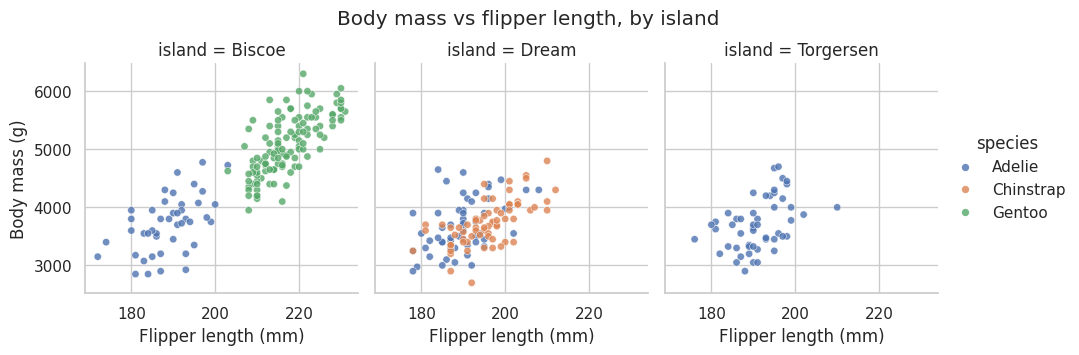

[PASS] C1: faceted figure saved with one panel per island


In [8]:
# C1: small multiples with Seaborn (faceting by island)
g = sns.relplot(data=clean, x="flipper_length_mm", y="body_mass_g", hue="species", col="island", kind="scatter", height=3.4, aspect=0.95, s=28, alpha=.8)
g.set_axis_labels("Flipper length (mm)", "Body mass (g)"); g.fig.suptitle("Body mass vs flipper length, by island", y=1.04)
g.fig.savefig(FIG / "t4_01_small_multiples.png", dpi=130, bbox_inches="tight"); plt.show()
check("C1", "Seaborn", "faceted figure saved with one panel per island", (FIG / "t4_01_small_multiples.png").exists() and len(g.axes.flat) == clean["island"].nunique())

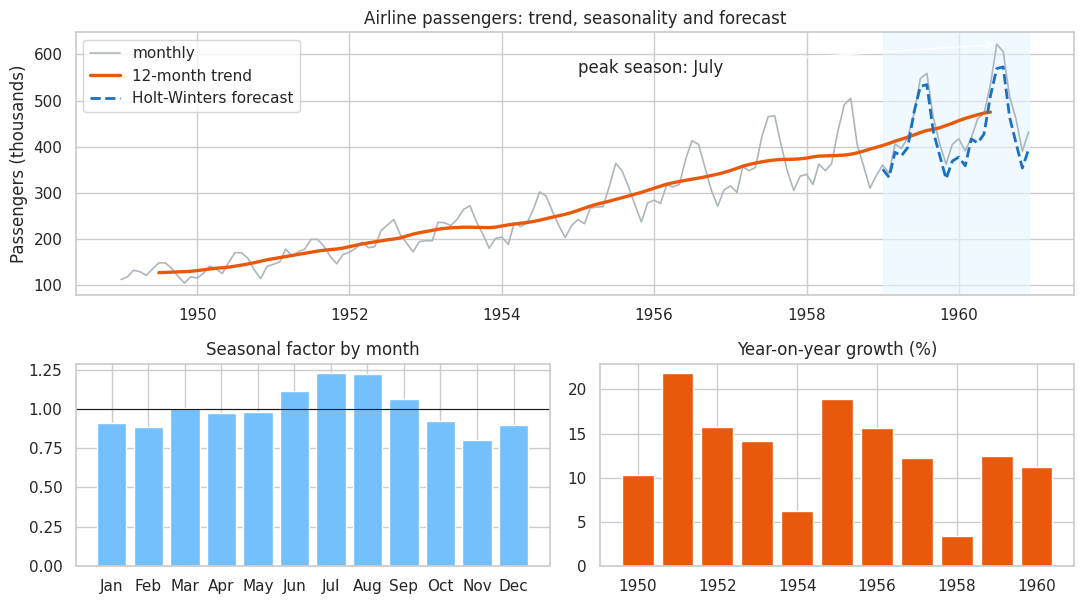

[PASS] C2: multi-panel figure saved


In [9]:
# C2: a custom multi-panel Matplotlib figure with annotation (GridSpec)
fig = plt.figure(figsize=(11, 6.2)); gs = fig.add_gridspec(2, 2, height_ratios=[1.3, 1])
ax1 = fig.add_subplot(gs[0, :]); ax2 = fig.add_subplot(gs[1, 0]); ax3 = fig.add_subplot(gs[1, 1])
ax1.plot(ts.index, ts.values, color="#adb5bd", lw=1.2, label="monthly"); ax1.plot(dec.trend.index, dec.trend.values, color="#E8590C", lw=2.4, label="12-month trend")
ax1.plot(test.index, hw.values, color="#1971C2", ls="--", lw=2, label="Holt-Winters forecast")
ax1.axvspan(test.index[0], test.index[-1], color="#e7f5ff", alpha=.6)
ax1.annotate(f"peak season: {peak_month}", xy=(ts.idxmax(), ts.max()), xytext=(pd.Timestamp("1955-01-01"), 560), arrowprops=dict(arrowstyle="->"))
ax1.set(title="Airline passengers: trend, seasonality and forecast", ylabel="Passengers (thousands)"); ax1.legend(loc="upper left")
ax2.bar(seasonal.index.strftime("%b"), seasonal.values, color="#74c0fc"); ax2.axhline(1, color="k", lw=.8); ax2.set(title="Seasonal factor by month")
ax3.bar(yoy.index.year, yoy.values * 100, color="#E8590C"); ax3.set(title="Year-on-year growth (%)")
save_fig(fig, "t4_02_timeseries_panel.png")
check("C2", "Matplotlib", "multi-panel figure saved", (FIG / "t4_02_timeseries_panel.png").exists())

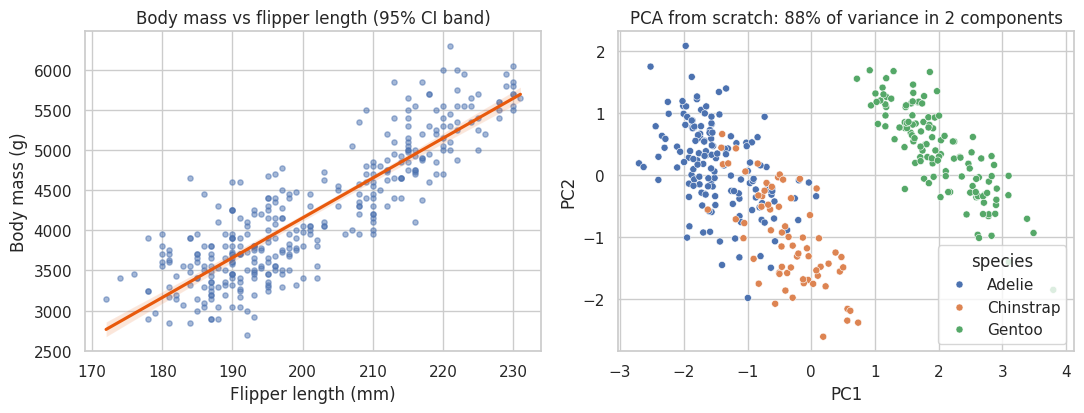

[PASS] C3: regression and PCA figure saved


In [10]:
# C3: regression plot with confidence band + PCA scatter coloured by species
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
sns.regplot(data=clean, x="flipper_length_mm", y="body_mass_g", scatter_kws=dict(s=14, alpha=.5), line_kws=dict(color="#E8590C"), ax=axes[0])
axes[0].set(title="Body mass vs flipper length (95% CI band)", xlabel="Flipper length (mm)", ylabel="Body mass (g)")
pc = pd.DataFrame(scores[:, :2], columns=["PC1", "PC2"]).assign(species=species_for_Z.to_numpy())
sns.scatterplot(data=pc, x="PC1", y="PC2", hue="species", s=26, ax=axes[1])
axes[1].set(title=f"PCA from scratch: {explained[:2].sum():.0%} of variance in 2 components")
save_fig(fig, "t4_03_regression_and_pca.png")
check("C3", "Seaborn", "regression and PCA figure saved", (FIG / "t4_03_regression_and_pca.png").exists())

## D. SciPy and statsmodels

### D1. ANOVA with effect size and Tukey post-hoc test

In [11]:
groups = [g["body_mass_g"].to_numpy() for _, g in clean.groupby("species", observed=True)]
F, p = stats.f_oneway(*groups)
grand = clean["body_mass_g"].mean()
eta2 = sum(len(g) * (g.mean() - grand) ** 2 for g in groups) / ((clean["body_mass_g"] - grand) ** 2).sum()
print(f"ANOVA: F = {F:.1f}, p = {p:.2g}, eta-squared = {eta2:.2f}")
tuk = pairwise_tukeyhsd(clean["body_mass_g"], clean["species"].astype(str))
tdf = pd.DataFrame(tuk._results_table.data[1:], columns=tuk._results_table.data[0]); display(tdf)
RESULTS["d1"] = {"F": float(F), "p": float(p), "eta2": float(eta2), "tukey_significant_pairs": int(tdf["reject"].sum())}
check("D1", "SciPy", "species explains a large share of body-mass variance (eta2 > 0.5)", p < 0.001 and eta2 > 0.5, f"eta2 = {eta2:.2f}")
check("D1", "statsmodels", "Tukey HSD finds exactly 2 of 3 species pairs differ (Adelie and Chinstrap are similar)", tdf["reject"].sum() == 2)

ANOVA: F = 343.6, p = 2.9e-82, eta-squared = 0.67


,group1,group2,meandiff,p-adj,lower,upper,reject
0,Adelie,Chinstrap,32.426,0.8807,-126.5002,191.3522,False
1,Adelie,Gentoo,1375.354,0.0000,1243.1786,1507.5294,True
2,Chinstrap,Gentoo,1342.928,0.0000,1178.4810,1507.3750,True


[PASS] D1: species explains a large share of body-mass variance (eta2 > 0.5)  (eta2 = 0.67)
[PASS] D1: Tukey HSD finds exactly 2 of 3 species pairs differ (Adelie and Chinstrap are similar)


### D2. OLS with inference and diagnostics

In [12]:
ols = smf.ols("body_mass_g ~ flipper_length_mm + C(species) + C(sex)", data=clean[clean["sex"] != "Unknown"]).fit()
print(f"R2 = {ols.rsquared:.3f}, adjusted R2 = {ols.rsquared_adj:.3f}, n = {int(ols.nobs)}")
display(pd.concat([ols.params.rename("coef"), ols.conf_int().rename(columns={0: "ci_low", 1: "ci_high"}), ols.pvalues.rename("p")], axis=1).round(3))
resid = ols.resid
sh_p = stats.shapiro(resid).pvalue; bp_p = het_breuschpagan(resid, ols.model.exog)[1]
X_vif = sm.add_constant(clean[["flipper_length_mm", "bill_length_mm", "bill_depth_mm"]])
vif = pd.Series([variance_inflation_factor(X_vif.to_numpy(), i) for i in range(1, X_vif.shape[1])], index=X_vif.columns[1:]).round(2)
print("Shapiro p (residual normality):", round(sh_p, 3), "| Breusch-Pagan p (constant variance):", round(bp_p, 3)); print("VIF:", vif.to_dict())
RESULTS["d2"] = {"r2": float(ols.rsquared), "adj_r2": float(ols.rsquared_adj), "shapiro_p": float(sh_p), "bp_p": float(bp_p),
                 "flipper_coef": float(ols.params["flipper_length_mm"]), "male_coef": float(ols.params["C(sex)[T.Male]"])}
check("D2", "statsmodels", "model explains most variance (R2 > 0.85)", ols.rsquared > 0.85)
check("D2", "statsmodels", "male coefficient is positive and significant", ols.params["C(sex)[T.Male]"] > 0 and ols.pvalues["C(sex)[T.Male]"] < 0.001)

R2 = 0.867, adjusted R2 = 0.865, n = 333


,coef,ci_low,ci_high,p
Intercept,-365.817,-1412.479,680.844,0.492
C(species)[T.Chinstrap],-87.634,-178.810,3.541,0.060
C(species)[T.Gentoo],836.260,668.681,1003.839,0.000
C(sex)[T.Male],530.381,456.000,604.762,0.000
flipper_length_mm,20.025,14.427,25.623,0.000


Shapiro p (residual normality):

 0.817 | Breusch-Pagan p (constant variance): 0.06
VIF: {'flipper_length_mm': 2.67, 'bill_length_mm': 1.87, 'bill_depth_mm': 1.61}
[PASS] D2: model explains most variance (R2 > 0.85)
[PASS] D2: male coefficient is positive and significant


### D3. Permutation test (SciPy)
**Task.** Are male Gentoo penguins heavier than females? Test with `scipy.stats.permutation_test` instead of assuming normality.

In [13]:
gen = clean[clean["species"] == "Gentoo"]
m, f = gen.loc[gen["sex"] == "Male", "body_mass_g"].to_numpy(), gen.loc[gen["sex"] == "Female", "body_mass_g"].to_numpy()
res = stats.permutation_test((m, f), lambda a, b: a.mean() - b.mean(), n_resamples=9999, alternative="greater", random_state=SEED)
print(f"mean difference = {m.mean() - f.mean():.0f} g, permutation p = {res.pvalue:.4f}")
RESULTS["d3"] = {"diff": float(m.mean() - f.mean()), "p": float(res.pvalue)}
check("D3", "SciPy", "permutation test confirms males are heavier (p < 0.001)", res.pvalue < 0.001)

mean difference = 805 g, permutation p = 0.0001
[PASS] D3: permutation test confirms males are heavier (p < 0.001)


## E. scikit-learn and LightGBM

### E1. Pipelines, repeated cross-validation and model comparison
**Task.** Predict penguin sex from measurements, species and island. Compare a baseline and three models under repeated stratified cross-validation with all preprocessing inside the pipeline.

In [14]:
data = clean[clean["sex"].isin(["Male", "Female"])].copy()
Xs, ys = data[num_cols + ["species", "island"]], (data["sex"] == "Male").astype(int)
pre = ColumnTransformer([("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
                         ("cat", OneHotEncoder(handle_unknown="ignore"), ["species", "island"])])
models = {"Dummy (majority)": DummyClassifier(strategy="most_frequent"),
          "Logistic regression": LogisticRegression(max_iter=2000),
          "Random forest": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1),
          "LightGBM": LGBMClassifier(n_estimators=200, learning_rate=.05, random_state=SEED, verbose=-1, n_jobs=1)}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
rows = []
for name, est in models.items():
    r = cross_validate(Pipeline([("pre", pre), ("clf", est)]), Xs, ys, cv=cv, scoring=["accuracy", "roc_auc"], n_jobs=1)
    rows.append({"model": name, "accuracy": r["test_accuracy"].mean(), "acc_sd": r["test_accuracy"].std(), "roc_auc": r["test_roc_auc"].mean(), "auc_sd": r["test_roc_auc"].std()})
cmp_df = pd.DataFrame(rows).set_index("model").round(3); display(cmp_df)
RESULTS["e1"] = cmp_df.reset_index().to_dict("records")
check("E1", "scikit-learn", "logistic regression beats the majority baseline by > 0.3 accuracy", cmp_df.loc["Logistic regression", "accuracy"] - cmp_df.loc["Dummy (majority)", "accuracy"] > 0.3)
check("E1", "scikit-learn", "best model reaches ROC-AUC > 0.95 under repeated CV", cmp_df["roc_auc"].max() > 0.95, f"{cmp_df['roc_auc'].max():.3f}")

,accuracy,acc_sd,roc_auc,auc_sd
model,,,,
Dummy (majority),0.504,0.004,0.500,0.000
Logistic regression,0.912,0.035,0.970,0.020
Random forest,0.911,0.044,0.969,0.022
LightGBM,0.910,0.039,0.971,0.019


[PASS] E1: logistic regression beats the majority baseline by > 0.3 accuracy
[PASS] E1: best model reaches ROC-AUC > 0.95 under repeated CV  (0.971)


### E2. Hyperparameter tuning

In [15]:
pipe = Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=3000))])
gs = GridSearchCV(pipe, {"clf__C": [0.01, 0.1, 1, 10, 100]}, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="roc_auc").fit(Xs, ys)
print("best C:", gs.best_params_["clf__C"], "| CV ROC-AUC:", round(gs.best_score_, 4))
display(pd.DataFrame(gs.cv_results_)[["param_clf__C", "mean_test_score", "std_test_score"]].round(4))
RESULTS["e2"] = {"best_C": float(gs.best_params_["clf__C"]), "best_auc": float(gs.best_score_)}
check("E2", "scikit-learn", "grid search finds a C at least as good as the default", gs.best_score_ >= cmp_df.loc["Logistic regression", "roc_auc"] - 0.01)

best C: 100 | CV ROC-AUC: 0.9732


,param_clf__C,mean_test_score,std_test_score
0,0.01,0.9314,0.0341
1,0.10,0.9646,0.0262
2,1.00,0.9710,0.0262
3,10.00,0.9721,0.0297
4,100.00,0.9732,0.0287


[PASS] E2: grid search finds a C at least as good as the default


### E3. Data leakage: the most common ML mistake
**Task.** Show with pure noise that selecting features on *all* the data before cross-validation produces a fake result, and that putting selection **inside** the pipeline gives the honest answer (chance level).

In [16]:
rng = np.random.default_rng(SEED)
Xn, yn = rng.normal(size=(100, 2000)), rng.integers(0, 2, 100)          # features and labels are independent noise
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)

leaky_X = SelectKBest(f_classif, k=20).fit_transform(Xn, yn)              # WRONG: selection saw every label
leaky = cross_val_score(LogisticRegression(max_iter=2000), leaky_X, yn, cv=cv5).mean()
honest = cross_val_score(Pipeline([("sel", SelectKBest(f_classif, k=20)), ("clf", LogisticRegression(max_iter=2000))]), Xn, yn, cv=cv5).mean()
print(f"leaky CV accuracy: {leaky:.2f}   |   correct (in-pipeline) CV accuracy: {honest:.2f}   |   truth: 0.50 (noise)")
RESULTS["e3"] = {"leaky": float(leaky), "honest": float(honest)}
check("E3", "scikit-learn", "leaky evaluation is inflated far above chance on pure noise", leaky > 0.75, f"{leaky:.2f}")
check("E3", "scikit-learn", "in-pipeline evaluation stays near chance (0.35-0.65)", 0.35 < honest < 0.65, f"{honest:.2f}")

leaky CV accuracy: 0.86   |   correct (in-pipeline) CV accuracy: 0.58   |   truth: 0.50 (noise)
[PASS] E3: leaky evaluation is inflated far above chance on pure noise  (0.86)
[PASS] E3: in-pipeline evaluation stays near chance (0.35-0.65)  (0.58)


### E4. Custom transformers from my `toolkit` package inside a pipeline, and a learning curve

Winsorizer pipeline CV ROC-AUC: 0.972
[PASS] E4: custom Winsorizer works inside ColumnTransformer + Pipeline


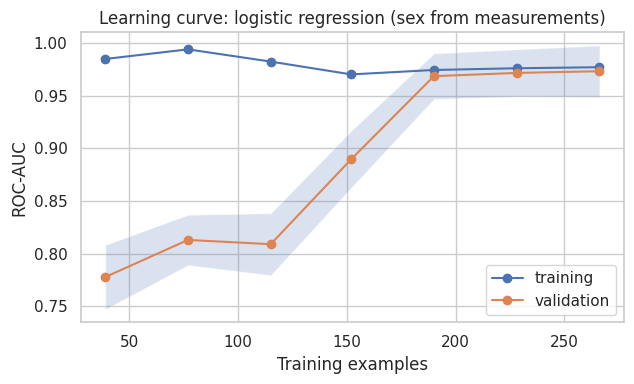

[PASS] E4: validation score is within 0.05 of training score (low overfitting)


In [17]:
num_only = Pipeline([("clip", Winsorizer(0.02, 0.98)), ("sc", StandardScaler())])
pre2 = ColumnTransformer([("num", num_only, num_cols), ("cat", OneHotEncoder(handle_unknown="ignore"), ["species", "island"])])
pipe2 = Pipeline([("pre", pre2), ("clf", LogisticRegression(max_iter=2000))])
acc2 = cross_val_score(pipe2, Xs, ys, cv=cv, scoring="roc_auc").mean()
print(f"Winsorizer pipeline CV ROC-AUC: {acc2:.3f}")
check("E4", "scikit-learn", "custom Winsorizer works inside ColumnTransformer + Pipeline", acc2 > 0.9)

sizes, tr, va = learning_curve(pipe2, Xs, ys, cv=cv5, scoring="roc_auc", train_sizes=np.linspace(.15, 1, 7), random_state=SEED)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(sizes, tr.mean(1), "o-", label="training"); ax.plot(sizes, va.mean(1), "o-", label="validation")
ax.fill_between(sizes, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=.2)
ax.set(title="Learning curve: logistic regression (sex from measurements)", xlabel="Training examples", ylabel="ROC-AUC"); ax.legend()
save_fig(fig, "t4_04_learning_curve.png")
check("E4", "scikit-learn", "validation score is within 0.05 of training score (low overfitting)", tr.mean(1)[-1] - va.mean(1)[-1] < 0.05)

## Scoreboard

In [18]:
board = pd.DataFrame(CHECKS)
display(board[["exercise", "tool", "check", "passed"]])
print(f"{board['passed'].sum()} of {len(board)} checks passed across {board['tool'].nunique()} tool groups")
RESULTS["n_checks"], RESULTS["n_passed"] = int(len(board)), int(board["passed"].sum())
RESULTS["checks"] = CHECKS
(ROOT / "outputs" / "exercise_results.json").write_text(json.dumps(RESULTS, indent=2, default=float))

,exercise,tool,check,passed
0,A1,NumPy,broadcast result equals loop result and SciPy ...,True
1,A1,NumPy,vectorised version is clearly faster than the ...,True
2,A2,NumPy,explained variance matches sklearn PCA,True
3,A2,NumPy,principal axes match sklearn up to sign,True
4,A2,NumPy,PC scores are uncorrelated,True
5,A3,NumPy,lstsq coefficients match scikit-learn,True
6,A3,NumPy,bootstrap CI brackets the least-squares slope,True
7,B1,Pandas,no missing values remain in the measurement co...,True
8,B1,Pandas,within-species z-scores have mean 0 and std 1,True
9,B1,Pandas,crosstab grand total equals number of rows,True


31 of 31 checks passed across 9 tool groups


7275